# 07 · Evaluasi Model Final
## California House Price Prediction menggunakan MLP Regression

Notebook ini mengevaluasi model final yang digunakan pada aplikasi. Evaluasi mencakup metrik regresi, kurva training dan validation, perbandingan skenario eksperimen, analisis kesalahan prediksi, serta pemeriksaan overfitting dan underfitting.

**Catatan metodologis:** proyek ini merupakan regresi, bukan klasifikasi. Karena itu, accuracy, precision, recall, dan F1-score tidak sesuai untuk menilai performa model. Notebook menggunakan MAE, RMSE, dan R². Kurva MAE ditampilkan sebagai ukuran performa per epoch, bukan accuracy.

## 0. Setup dan pemuatan artefak

Notebook membaca model dan preprocessing yang sama dengan aplikasi (`backend/artifacts/`). Notebook tidak melatih ulang model final sehingga hasil evaluasi tetap merujuk pada artefak yang digunakan aplikasi.

Jalankan notebook dari folder utama repository atau melalui Google Colab.

In [1]:
import os, sys, json, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
SEED = 42
TARGET = "median_house_value"
TARGET_SCALE = 100_000.0
REPO_URL = "https://github.com/lukito789/california-house-price-mlp.git"

if "google.colab" in sys.modules:
    ROOT = Path("/content/california-house-price-mlp")
    if not ROOT.exists():
        subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
else:
    ROOT = Path.cwd()
    if not (ROOT / "data" / "housing.csv").exists():
        ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "backend"))
from preprocess import fit_prep, transform

DATA_PATH = ROOT / "data" / "housing.csv"
MODEL_PATH = ROOT / "backend" / "artifacts" / "model.keras"
PREP_PATH = ROOT / "backend" / "artifacts" / "prep.json"
METRICS_PATH = ROOT / "backend" / "artifacts" / "metrics.json"
CONF_PATH = ROOT / "data" / "processed" / "conformal.json"
OOD_PATH = ROOT / "data" / "processed" / "ood.json"

for p in [DATA_PATH, MODEL_PATH, PREP_PATH, METRICS_PATH]:
    if not p.exists():
        raise FileNotFoundError(f"File wajib tidak ditemukan: {p}")

print("ROOT:", ROOT)
print("Dataset:", DATA_PATH)
print("Model:", MODEL_PATH)

ROOT: /content/california-house-price-mlp
Dataset: /content/california-house-price-mlp/data/housing.csv
Model: /content/california-house-price-mlp/backend/artifacts/model.keras


## 1. Metrik evaluasi dan alasan pemilihan

Tiga metrik digunakan karena masing-masing menjelaskan aspek kesalahan regresi yang berbeda.

- **MAE (Mean Absolute Error):** rata-rata selisih absolut antara prediksi dan nilai sebenarnya. Satuan metrik ini adalah USD sehingga mudah ditafsirkan.
- **RMSE (Root Mean Squared Error):** memberi penalti lebih besar pada kesalahan yang besar. Metrik ini membantu melihat dampak prediksi yang meleset jauh.
- **R² (Coefficient of Determination):** mengukur proporsi variasi target yang dapat dijelaskan model. Nilai yang lebih tinggi menunjukkan kecocokan yang lebih baik, tetapi tidak berarti prediksi selalu akurat.

Accuracy tidak dihitung karena target `median_house_value` berupa nilai kontinu, bukan label kelas.

In [2]:
import tensorflow as tf
from tensorflow import keras

df = pd.read_csv(DATA_PATH).dropna(subset=[TARGET, "ocean_proximity"])
df = df.sample(frac=1.0, random_state=SEED).reset_index(drop=True)

n = len(df)
n_train = int(n * 0.70)
n_val = int(n * 0.15)
train_df = df.iloc[:n_train].copy()
val_df = df.iloc[n_train:n_train+n_val].copy()
test_df = df.iloc[n_train+n_val:].copy()

prep = json.loads(PREP_PATH.read_text())
model = keras.models.load_model(MODEL_PATH)

X_train = transform(train_df, prep)
X_val = transform(val_df, prep)
X_test = transform(test_df, prep)
y_train = train_df[TARGET].to_numpy(dtype="float64")
y_val = val_df[TARGET].to_numpy(dtype="float64")
y_test = test_df[TARGET].to_numpy(dtype="float64")

def predict_usd(X):
    return np.maximum(model.predict(X, verbose=0).reshape(-1) * TARGET_SCALE, 0)

pred_train = predict_usd(X_train)
pred_val = predict_usd(X_val)
pred_test = predict_usd(X_test)

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print("Jumlah fitur input:", X_train.shape[1])

Train: 14,447 | Validation: 3,096 | Test: 3,097
Jumlah fitur input: 13


## 2. Nilai metrik pada data testing

Bagian ini menghitung ulang MAE, RMSE, dan R² pada data testing. Data testing tidak digunakan untuk melatih model atau memilih hyperparameter. Nilai hasil hitung ulang dibandingkan dengan `metrics.json` yang disimpan bersama model.

In [3]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE (USD)": mean_absolute_error(y_true, y_pred),
        "RMSE (USD)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }

metric_table = pd.DataFrame({
    "Training": regression_metrics(y_train, pred_train),
    "Validation": regression_metrics(y_val, pred_val),
    "Testing": regression_metrics(y_test, pred_test)
}).T
display(metric_table.style.format({
    "MAE (USD)": "${:,.2f}", "RMSE (USD)": "${:,.2f}", "R²": "{:.4f}"
}))

saved_metrics = json.loads(METRICS_PATH.read_text())
print("\nMetrik testing yang tersimpan pada metrics.json:")
print(f"MAE  : ${saved_metrics['test_mae_usd']:,.2f}")
print(f"RMSE : ${saved_metrics['test_rmse_usd']:,.2f}")
print(f"R²   : {saved_metrics['test_r2']:.4f}")

,MAE (USD),RMSE (USD),R²
Training,"$29,625.49","$44,010.99",0.8543
Validation,"$31,778.75","$48,497.38",0.8203
Testing,"$33,021.33","$49,394.59",0.8212



Metrik testing yang tersimpan pada metrics.json:
MAE  : $33,021.33
RMSE : $49,394.59
R²   : 0.8212


## 3. Grafik loss dan performa training-validation

Untuk regresi, grafik accuracy tidak relevan. Sebagai gantinya, notebook menampilkan **loss (MSE)** dan **MAE** pada data training dan validation. Kurva validation membantu melihat apakah model mulai kehilangan kemampuan generalisasi selama training.

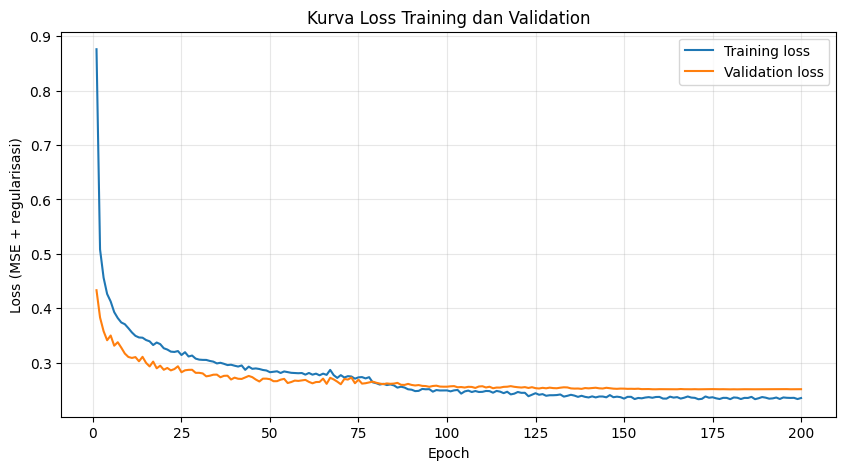

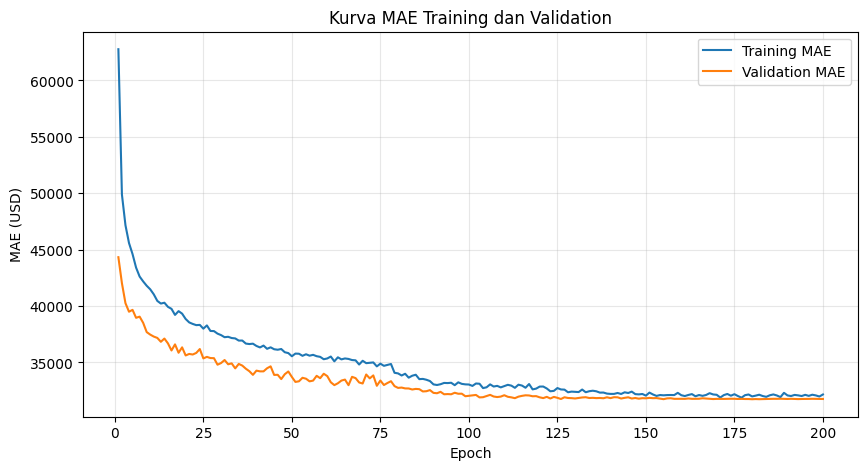

In [4]:
history = saved_metrics.get("history", {})
if not all(k in history for k in ["loss", "val_loss"]):
    print("Riwayat loss tidak tersedia di metrics.json.")
else:
    epochs = np.arange(1, len(history["loss"]) + 1)
    plt.figure(figsize=(10, 5))
    plt.plot(epochs, history["loss"], label="Training loss")
    plt.plot(epochs, history["val_loss"], label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE + regularisasi)")
    plt.title("Kurva Loss Training dan Validation")
    plt.legend()
    plt.grid(alpha=.3)
    plt.show()

if all(k in history for k in ["mae", "val_mae"]):
    plt.figure(figsize=(10, 5))
    plt.plot(np.arange(1, len(history["mae"])+1), np.array(history["mae"])*TARGET_SCALE,
             label="Training MAE")
    plt.plot(np.arange(1, len(history["val_mae"])+1), np.array(history["val_mae"])*TARGET_SCALE,
             label="Validation MAE")
    plt.xlabel("Epoch")
    plt.ylabel("MAE (USD)")
    plt.title("Kurva MAE Training dan Validation")
    plt.legend()
    plt.grid(alpha=.3)
    plt.show()
else:
    print("Riwayat MAE tidak tersedia di metrics.json.")

## 4. Perbandingan antarskenario eksperimen

Notebook 04 menguji perubahan satu faktor pada satu waktu. Tabel berikut merangkum hasil screening validation yang tercatat pada eksperimen tersebut. Angka ini merupakan hasil screening satu seed, sehingga digunakan untuk membandingkan kecenderungan, bukan sebagai hasil akhir pada test.

Aturan pemilihan Notebook 04 mempertimbangkan variasi antar-seed dan ambang perbaikan. Karena kandidat tidak menunjukkan peningkatan yang cukup kuat menurut aturan tersebut, model baseline tetap dipilih sebagai model final.

,Skenario,Konfigurasi,Validation MAE (USD),Selisih dari baseline (USD)
3,Target log,Target ditransformasi log,"$31,442",$-929
2,Arsitektur lebih besar,256-128-64,"$31,535",$-836
1,Dropout 0.1,Dropout=0.1,"$32,034",$-337
0,Baseline,128-64-32; L2=1e-4; dropout=0.2; lr=0.001; batch=64,"$32,371",$0
4,Fitur rasio,16 fitur termasuk fitur rasio,"$32,605",$234
6,Learning rate 0.0003,lr=0.0003,"$34,975","$2,604"
5,Learning rate 0.01,lr=0.01,"$35,798","$3,427"


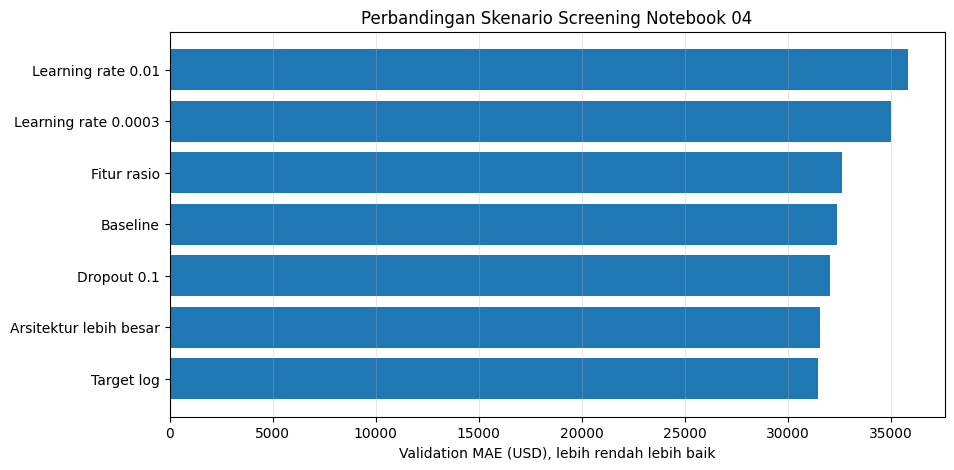

Catatan: hasil screening memakai seed tunggal. Model final tetap baseline berdasarkan protokol seleksi multi-seed Notebook 04.


In [5]:
screening = pd.DataFrame([
    ["Baseline", "128-64-32; L2=1e-4; dropout=0.2; lr=0.001; batch=64", 32371],
    ["Dropout 0.1", "Dropout=0.1", 32034],
    ["Arsitektur lebih besar", "256-128-64", 31535],
    ["Target log", "Target ditransformasi log", 31442],
    ["Fitur rasio", "16 fitur termasuk fitur rasio", 32605],
    ["Learning rate 0.01", "lr=0.01", 35798],
    ["Learning rate 0.0003", "lr=0.0003", 34975],
], columns=["Skenario", "Konfigurasi", "Validation MAE (USD)"])
screening["Selisih dari baseline (USD)"] = screening["Validation MAE (USD)"] - 32371
display(screening.sort_values("Validation MAE (USD)").style.format({
    "Validation MAE (USD)": "${:,.0f}", "Selisih dari baseline (USD)": "${:,.0f}"
}))

plt.figure(figsize=(10, 5))
plot_df = screening.sort_values("Validation MAE (USD)")
plt.barh(plot_df["Skenario"], plot_df["Validation MAE (USD)"])
plt.xlabel("Validation MAE (USD), lebih rendah lebih baik")
plt.title("Perbandingan Skenario Screening Notebook 04")
plt.grid(axis="x", alpha=.3)
plt.show()

print("Catatan: hasil screening memakai seed tunggal. Model final tetap baseline berdasarkan protokol seleksi multi-seed Notebook 04.")

### Perbandingan dengan dan tanpa fitur tambahan

Conformal Prediction dan OOD Detection merupakan lapisan evaluasi kepercayaan terhadap prediksi. Keduanya tidak mengubah bobot MLP atau nilai prediksi titik. Conformal Prediction menambahkan interval, sedangkan OOD Detection memberi peringatan untuk input yang tidak menyerupai distribusi data training.

In [6]:
if CONF_PATH.exists():
    conf = json.loads(CONF_PATH.read_text())
    print("Conformal Prediction:")
    print("Metode:", conf.get("metode"))
    print("Jumlah data kalibrasi:", conf.get("n_kalibrasi"))
    ct = conf.get("cakupan_test", {})
    print(f"Cakupan interval 90% pada test: {ct.get('cakupan', float('nan'))*100:.2f}%")
    print(f"Lebar interval rata-rata: ${ct.get('lebar_rata2_usd', float('nan')):,.2f}")
else:
    print("conformal.json tidak ditemukan. Jalankan Notebook 05.")

if OOD_PATH.exists():
    ood = json.loads(OOD_PATH.read_text())
    print("\nOOD Detection:")
    print("Metode:", ood.get("metode"))
    print("Persentil:", ood.get("persentil"))
    print("Ambang:", ood.get("ambang"))
    print(f"False positive validation: {ood.get('fpr_validation_persen', float('nan')):.2f}%")
else:
    print("ood.json tidak ditemukan. Jalankan Notebook 06.")

Conformal Prediction:
Metode: relatif
Jumlah data kalibrasi: 3096
Cakupan interval 90% pada test: 89.80%
Lebar interval rata-rata: $145,836.25

OOD Detection:
Metode: mahalanobis
Persentil: 99.0
Ambang: 7.264026833890815
False positive validation: 0.84%


## 5. Analisis hasil dan kesalahan prediksi

Pada regresi, tidak ada kelas yang salah diprediksi. Analisis dilakukan dengan melihat kelompok harga yang memiliki kesalahan prediksi terbesar. Bagian ini juga menampilkan contoh observasi dengan residual absolut tertinggi dan kemungkinan penyebabnya.

,kelompok_harga,jumlah,MAE,bias_rata2
0,< $100k,551,"$19,114","$15,814"
1,$100k-$200k,"1,241","$24,733","$10,478"
2,$200k-$300k,722,"$34,241",$-317
3,$300k-$400k,309,"$53,447","$-30,538"
4,$400k-$500k,274,"$72,278","$-69,345"


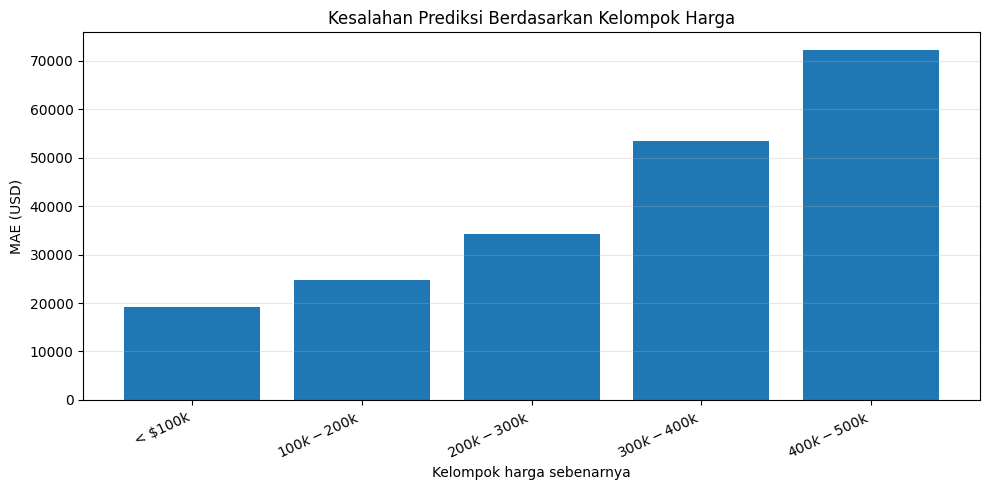

In [7]:
error_df = test_df[["median_house_value", "ocean_proximity", "latitude", "longitude"]].copy()
error_df["prediksi_usd"] = pred_test
error_df["error_usd"] = error_df["prediksi_usd"] - error_df["median_house_value"]
error_df["absolute_error_usd"] = error_df["error_usd"].abs()

bins = [0, 100000, 200000, 300000, 400000, 500001]
labels = ["< $100k", "$100k-$200k", "$200k-$300k", "$300k-$400k", "$400k-$500k"]
error_df["kelompok_harga"] = pd.cut(
    error_df["median_house_value"].clip(upper=500000),
    bins=bins, labels=labels, include_lowest=True
)

by_price = error_df.groupby("kelompok_harga", observed=False).agg(
    jumlah=("error_usd", "size"),
    MAE=("absolute_error_usd", "mean"),
    bias_rata2=("error_usd", "mean")
).reset_index()
display(by_price.style.format({
    "MAE": "${:,.0f}", "bias_rata2": "${:,.0f}", "jumlah": "{:,.0f}"
}))

plt.figure(figsize=(10, 5))
plt.bar(by_price["kelompok_harga"].astype(str), by_price["MAE"])
plt.xticks(rotation=25, ha="right")
plt.ylabel("MAE (USD)")
plt.xlabel("Kelompok harga sebenarnya")
plt.title("Kesalahan Prediksi Berdasarkan Kelompok Harga")
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

In [8]:
print("10 observasi dengan kesalahan absolut terbesar:")
display(error_df.sort_values("absolute_error_usd", ascending=False).head(10).style.format({
    "median_house_value": "${:,.0f}",
    "prediksi_usd": "${:,.0f}",
    "error_usd": "${:,.0f}",
    "absolute_error_usd": "${:,.0f}",
    "latitude": "{:.3f}", "longitude": "{:.3f}"
}))

print("\nMAE berdasarkan kategori kedekatan laut:")
by_ocean = error_df.groupby("ocean_proximity").agg(
    jumlah=("error_usd", "size"),
    MAE=("absolute_error_usd", "mean"),
    bias_rata2=("error_usd", "mean")
).sort_values("MAE", ascending=False)
display(by_ocean.style.format({
    "MAE": "${:,.0f}", "bias_rata2": "${:,.0f}", "jumlah": "{:,.0f}"
}))

10 observasi dengan kesalahan absolut terbesar:


,median_house_value,ocean_proximity,latitude,longitude,prediksi_usd,error_usd,absolute_error_usd,kelompok_harga
19102,"$500,001",NEAR BAY,37.800,-122.270,"$143,979","$-356,022","$356,022",$400k-$500k
18789,"$500,001",<1H OCEAN,33.680,-117.810,"$203,782","$-296,219","$296,219",$400k-$500k
19367,"$450,000",<1H OCEAN,33.690,-117.810,"$163,690","$-286,310","$286,310",$400k-$500k
18943,"$500,001",NEAR BAY,37.810,-122.470,"$219,592","$-280,409","$280,409",$400k-$500k
19054,"$500,001",<1H OCEAN,34.060,-118.310,"$225,928","$-274,073","$274,073",$400k-$500k
19524,"$500,001",NEAR OCEAN,34.230,-119.140,"$229,993","$-270,008","$270,008",$400k-$500k
20357,"$475,000",<1H OCEAN,34.060,-118.300,"$216,663","$-258,337","$258,337",$400k-$500k
20584,"$500,001",<1H OCEAN,33.620,-117.940,"$253,540","$-246,461","$246,461",$400k-$500k
18484,"$350,000",<1H OCEAN,34.030,-118.280,"$104,501","$-245,499","$245,499",$300k-$400k
19882,"$445,000",<1H OCEAN,34.070,-118.310,"$207,433","$-237,567","$237,567",$400k-$500k



MAE berdasarkan kategori kedekatan laut:


,jumlah,MAE,bias_rata2
ocean_proximity,,,
ISLAND,1,"$85,534","$-85,534"
NEAR BAY,341,"$40,874","$-7,487"
NEAR OCEAN,361,"$40,496","$5,066"
<1H OCEAN,"1,416","$36,688","$-3,410"
INLAND,978,"$22,162","$-1,341"


### Interpretasi penyebab kesalahan

Periksa kelompok dengan MAE tertinggi dan observasi dengan residual terbesar. Beberapa kemungkinan penyebab yang relevan untuk dataset ini:

1. **Target memiliki batas atas sekitar USD 500.001.** Nilai rumah yang lebih mahal mengalami efek pemotongan (*capping*), sehingga model tidak dapat mempelajari variasi harga di atas batas tersebut secara penuh.
2. **Variasi harga di dalam satu blok sensus.** Dataset merepresentasikan median harga pada blok sensus, bukan karakteristik satu rumah secara individual.
3. **Informasi fitur terbatas.** Dataset tidak menyediakan kondisi bangunan, luas tanah, jumlah kamar mandi, tahun renovasi, dan karakteristik properti individual.
4. **Ketidakseimbangan rentang harga.** Kelompok harga tertentu dapat memiliki jumlah observasi lebih sedikit sehingga pola lebih sulit dipelajari.
5. **Lokasi dan kedekatan laut.** Hubungan lokasi dengan harga dapat bersifat kompleks dan tidak sepenuhnya tertangkap oleh fitur yang tersedia.

Poin-poin tersebut merupakan kemungkinan penjelasan. Gunakan tabel dan grafik di atas untuk menentukan faktor mana yang paling terlihat pada hasil aktual.

## 6. Diagnosis overfitting dan underfitting

Diagnosis dilakukan dengan membandingkan MAE training dan validation, melihat jarak kedua kurva, serta memeriksa pola loss.

- **Overfitting:** performa training jauh lebih baik daripada validation, sementara validation loss cenderung meningkat atau stagnan.
- **Underfitting:** kesalahan training dan validation sama-sama tinggi, yang menunjukkan model belum menangkap pola data dengan baik.
- **Generalisasi cukup baik:** nilai training dan validation relatif berdekatan dan keduanya menunjukkan kesalahan yang terkendali.

Penilaian tidak hanya didasarkan pada satu angka. Perhatikan juga bentuk kurva selama training.

In [9]:
diag = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "MAE (USD)": [
        mean_absolute_error(y_train, pred_train),
        mean_absolute_error(y_val, pred_val),
        mean_absolute_error(y_test, pred_test)
    ],
    "RMSE (USD)": [
        np.sqrt(mean_squared_error(y_train, pred_train)),
        np.sqrt(mean_squared_error(y_val, pred_val)),
        np.sqrt(mean_squared_error(y_test, pred_test))
    ],
    "R²": [
        r2_score(y_train, pred_train),
        r2_score(y_val, pred_val),
        r2_score(y_test, pred_test)
    ]
})
display(diag.style.format({
    "MAE (USD)": "${:,.0f}", "RMSE (USD)": "${:,.0f}", "R²": "{:.4f}"
}))

mae_train = diag.loc[diag["Dataset"]=="Training", "MAE (USD)"].iloc[0]
mae_validation = diag.loc[diag["Dataset"]=="Validation", "MAE (USD)"].iloc[0]
gap = mae_validation - mae_train
gap_pct = gap / mae_train * 100

print(f"Selisih MAE validation-training: ${gap:,.0f} ({gap_pct:.1f}% dari MAE training)")
if gap_pct > 25:
    print("Indikasi: terdapat gap generalisasi yang perlu diperiksa sebagai kemungkinan overfitting.")
elif gap_pct < 5:
    print("Indikasi: gap training-validation relatif kecil. Periksa juga apakah kedua MAE masih tinggi untuk menilai underfitting.")
else:
    print("Indikasi: terdapat gap moderat. Tidak cukup untuk menyimpulkan overfitting tanpa melihat kurva loss.")

,Dataset,MAE (USD),RMSE (USD),R²
0,Training,"$29,625","$44,011",0.8543
1,Validation,"$31,779","$48,497",0.8203
2,Testing,"$33,021","$49,395",0.8212


Selisih MAE validation-training: $2,153 (7.3% dari MAE training)
Indikasi: terdapat gap moderat. Tidak cukup untuk menyimpulkan overfitting tanpa melihat kurva loss.


## 7. Kesimpulan evaluasi final

Kesimpulan berikut dihasilkan dari metrik yang dihitung pada notebook ini. Perhatikan nilai testing sebagai hasil utama evaluasi generalisasi. Validation digunakan untuk pemilihan model, sedangkan training digunakan untuk memahami proses pembelajaran.

In [10]:
test_metrics = regression_metrics(y_test, pred_test)
val_metrics = regression_metrics(y_val, pred_val)
train_metrics = regression_metrics(y_train, pred_train)

print("KESIMPULAN EVALUASI MODEL FINAL")
print(f"- MAE testing : ${test_metrics['MAE (USD)']:,.2f}")
print(f"- RMSE testing: ${test_metrics['RMSE (USD)']:,.2f}")
print(f"- R² testing  : {test_metrics['R²']:.4f}")
print(f"- MAE training: ${train_metrics['MAE (USD)']:,.2f}")
print(f"- MAE validation: ${val_metrics['MAE (USD)']:,.2f}")

worst_group = by_price.sort_values("MAE", ascending=False).iloc[0]
print(f"- Kelompok harga dengan MAE tertinggi: {worst_group['kelompok_harga']} (MAE ${worst_group['MAE']:,.0f}).")
print("- Model final menggunakan MLP baseline 13-128-64-32-1.")
print("- Accuracy tidak digunakan karena masalah yang ditangani adalah regresi.")
print("- Interpretasi overfitting/underfitting harus mempertimbangkan gap metrik dan kurva training-validation.")

KESIMPULAN EVALUASI MODEL FINAL
- MAE testing : $33,021.33
- RMSE testing: $49,394.59
- R² testing  : 0.8212
- MAE training: $29,625.49
- MAE validation: $31,778.75
- Kelompok harga dengan MAE tertinggi: $400k-$500k (MAE $72,278).
- Model final menggunakan MLP baseline 13-128-64-32-1.
- Accuracy tidak digunakan karena masalah yang ditangani adalah regresi.
- Interpretasi overfitting/underfitting harus mempertimbangkan gap metrik dan kurva training-validation.


## 8. Ringkasan keterbatasan

- Prediksi merepresentasikan median harga rumah pada blok sensus California tahun 1990, bukan estimasi harga pasar saat ini.
- Batas atas target pada dataset dapat menyebabkan prediksi harga properti mahal kurang akurat.
- MAE dan RMSE bergantung pada distribusi harga dalam dataset.
- Interval Conformal Prediction memiliki cakupan empiris pada data uji, tetapi tidak menjamin cakupan untuk input yang jauh di luar distribusi training.
- OOD Detection memberi indikasi input tidak lazim, bukan jaminan bahwa semua input bermasalah akan terdeteksi.